## Análise Comparativa dos Modelos no SST

In [92]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from sklearn.metrics import accuracy_score, confusion_matrix
from IPython.display import display, HTML
from deep_translator import GoogleTranslator

plt.style.use('ggplot')
sns.set_palette("pastel")

In [93]:
# Função para estilização de DataFrames
def styled_sentiment_examples(df):
    return df.style.set_properties(**{
        'background-color': '#f8f9fa',
        'border': '1px solid #dee2e6',
        'padding': '5px',
        'color': '#212529'
    }).set_table_styles([{
        'selector': 'th',
        'props': [('background-color', '#343a40'), ('color', 'white')]
    }])

In [103]:
# Traduzir sentenças para português
def translate_sentence(sentence):
    try:
        return GoogleTranslator(source='en', target='pt').translate(sentence)
    except Exception as e:
        print(f"Erro ao traduzir: {e}")
        return sentence  # Retorna original se houver erro

## Análise do Modelo Base no SST

In [94]:
sst_dev = pd.read_csv('../data/ids-sst-dev.csv', sep='\t')
sst_pretrain = pd.read_csv('../predictions/sst_v1_base_model/pretrain-sst-dev-out.csv')
sst_finetune = pd.read_csv('../predictions/sst_v1_base_model/finetune-sst-dev-out.csv')

# Combinar dados
sst_base_analysis = sst_pretrain.merge(
    sst_finetune, on='id', suffixes=('_pretrain', '_finetune')
).merge(sst_dev, on='id')

### Métricas SST - Modelo Base

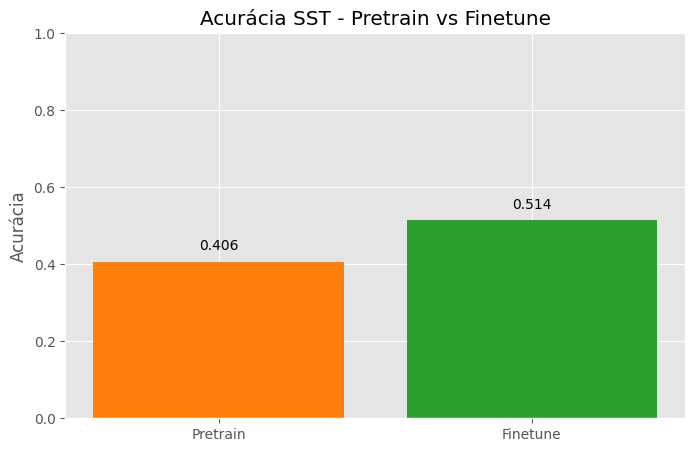

In [95]:
# Calcular acurácias
acc_pretrain_sst = accuracy_score(sst_base_analysis['sentiment'], sst_base_analysis['Predicted_Sentiment_pretrain'])
acc_finetune_sst = accuracy_score(sst_base_analysis['sentiment'], sst_base_analysis['Predicted_Sentiment_finetune'])

plt.figure(figsize=(8,5))
plt.bar(['Pretrain', 'Finetune'], [acc_pretrain_sst, acc_finetune_sst], color=['#ff7f0e', '#2ca02c'])
plt.title('Acurácia SST - Pretrain vs Finetune')
plt.ylim(0, 1)
plt.ylabel('Acurácia')
for i, v in enumerate([acc_pretrain_sst, acc_finetune_sst]):
    plt.text(i, v + 0.03, f"{v:.3f}", ha='center')
plt.show()

### Exemplos de Melhoria Pretrain -> Finetune no SST - Modelo Base

In [96]:
# Filtrar casos onde finetune corrigiu pretrain
sst_improvements = sst_base_analysis[
    (sst_base_analysis['Predicted_Sentiment_finetune'] == sst_base_analysis['sentiment']) &
    (sst_base_analysis['Predicted_Sentiment_pretrain'] != sst_base_analysis['sentiment'])
]


# quantidade de melhorias
n_improvements = sst_improvements.shape[0]
print(f"Quantidade de melhorias: {n_improvements}")

# 5 amostras para análise
sst_improvements = sst_improvements.sample(5)

Quantidade de melhorias: 228


In [104]:
# Mapear sentimentos
sentiment_map_sst = {
    0: 'Negative',
    1: 'Somewhat Negative',
    2: 'Neutral',
    3: 'Somewhat Positive',
    4: 'Positive'
}

examples_sst = sst_improvements.loc[:, ['sentence', 'sentiment', 'Predicted_Sentiment_pretrain', 'Predicted_Sentiment_finetune']]
examples_sst['sentence'] = examples_sst['sentence'].apply(translate_sentence)
examples_sst['sentiment'] = examples_sst['sentiment'].map(sentiment_map_sst)
examples_sst['Predicted_Sentiment_pretrain'] = examples_sst['Predicted_Sentiment_pretrain'].map(sentiment_map_sst)
examples_sst['Predicted_Sentiment_finetune'] = examples_sst['Predicted_Sentiment_finetune'].map(sentiment_map_sst)


display(styled_sentiment_examples(examples_sst.rename(columns={
    'sentiment': 'Real',
    'Predicted_Sentiment_pretrain': 'Pretrain',
    'Predicted_Sentiment_finetune': 'Finetune'
})))

,sentence,Real,Pretrain,Finetune
408,O enredo relativamente simples e a moral descomplicada do filme combinam bem com o elenco afável.,Somewhat Positive,Somewhat Negative,Somewhat Positive
769,"Há algo com potencial aqui, mas o filme decide, como Lavinia, seguir o caminho conservador.",Neutral,Somewhat Negative,Neutral
307,"Ancorado nas atuações excepcionais de Friel e Williams, o poder do filme está em sua complexidade.",Positive,Somewhat Positive,Positive
898,"Há uma história sólida de uma mulher se encontrando em algum lugar aqui, mas você teria que cavar bem fundo para descobri-la.",Neutral,Somewhat Negative,Neutral
949,"... buracos na trama tão grandes e óbvios que uma banda marcial poderia muito bem passar por eles vestida de palhaço, tocando uma música de luta de futebol americano universitário com instrumentos desafinados.",Negative,Somewhat Negative,Negative


### Nuvem de Palavras SST Base

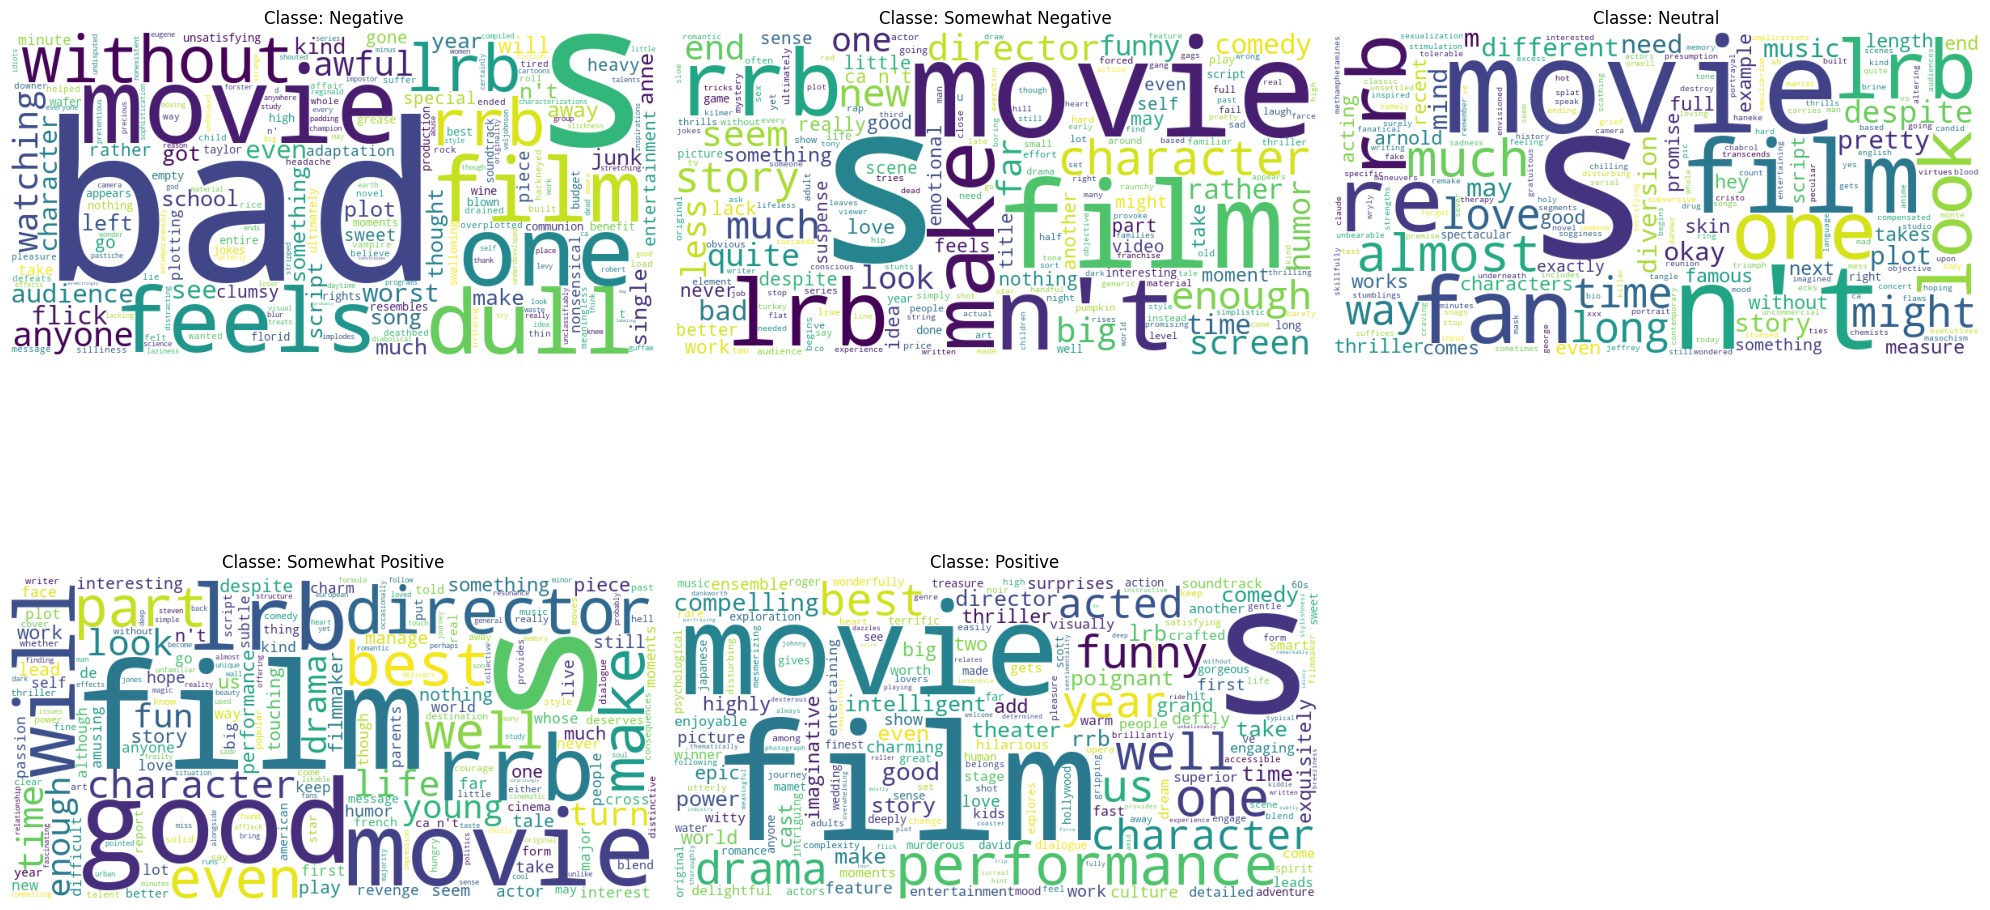

In [98]:
# Gerar word clouds para cada classe
def generate_sst_wordclouds(df):
    fig, axs = plt.subplots(2, 3, figsize=(20, 12))
    axs = axs.flatten()
    
    for i in range(5):
        text = ' '.join(df[df['sentiment'] == i]['sentence'].str.lower())
        text = text.replace("(RRB)", "").replace("(LRB)", "")
        wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)
        axs[i].imshow(wordcloud)
        axs[i].set_title(f'Classe: {sentiment_map_sst[i]}', fontsize=12)
        axs[i].axis('off')
    
    fig.delaxes(axs[5])
    plt.tight_layout()
    plt.show()


generate_sst_wordclouds(sst_base_analysis[sst_base_analysis['Predicted_Sentiment_finetune'] == sst_base_analysis['sentiment']])

## Análise da Versão Melhorada do Modelo no  SST

In [99]:
# Carregar dados da versão melhorada
improved_sst = pd.read_csv('../predictions/sst_v2/finetune-sst-dev-out.csv')

# Combinar com versão base
sst_comparison = sst_finetune.merge(
    improved_sst, on='id', suffixes=('_base', '_improved')
).merge(sst_dev, on='id')

 ### Comparação de Acurácia com o Modelo Base

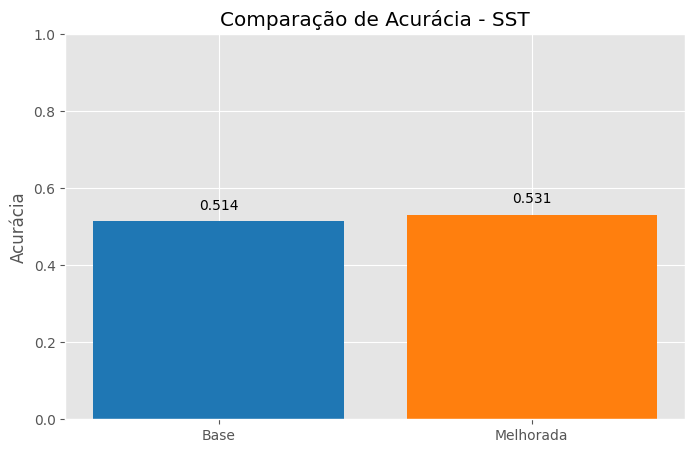

In [100]:
acc_base = accuracy_score(sst_comparison['sentiment'], sst_comparison['Predicted_Sentiment_base'])
acc_improved = accuracy_score(sst_comparison['sentiment'], sst_comparison['Predicted_Sentiment_improved'])

plt.figure(figsize=(8,5))
plt.bar(['Base', 'Melhorada'], [acc_base, acc_improved], color=['#1f77b4', '#ff7f0e'])
plt.title('Comparação de Acurácia - SST')
plt.ylim(0, 1)
plt.ylabel('Acurácia')
for i, v in enumerate([acc_base, acc_improved]):
    plt.text(i, v + 0.03, f"{v:.3f}", ha='center')
plt.show()


### Exemplos de Melhoria

In [106]:
improvements = sst_comparison[
    (sst_comparison['Predicted_Sentiment_improved'] == sst_comparison['sentiment']) &
    (sst_comparison['Predicted_Sentiment_base'] != sst_comparison['sentiment'])
].sample(5)

examples_improved = improvements.loc[:, ['sentence', 'sentiment', 'Predicted_Sentiment_base', 'Predicted_Sentiment_improved']]
examples_improved['sentence'] = examples_improved['sentence'].apply(translate_sentence)
examples_improved['sentiment'] = examples_improved['sentiment'].map(sentiment_map_sst)
examples_improved['Predicted_Sentiment_base'] = examples_improved['Predicted_Sentiment_base'].map(sentiment_map_sst)
examples_improved['Predicted_Sentiment_improved'] = examples_improved['Predicted_Sentiment_improved'].map(sentiment_map_sst)

display(styled_sentiment_examples(examples_improved.rename(columns={
    'sentiment': 'Real',
    'Predicted_Sentiment_base': 'Base',
    'Predicted_Sentiment_improved': 'Melhorada'
})))

,sentence,Real,Base,Melhorada
551,Lamento não ter conseguido captar todo o impacto da comédia.,Somewhat Negative,Neutral,Somewhat Negative
702,"É um entretenimento infantil realmente estranho, às vezes confuso... mas pelo menos desta vez há uma narrativa centrada para acompanhar todas as coisas estranhas.",Neutral,Somewhat Positive,Neutral
485,Um suspense psicológico tenso que não desperdiça um momento sequer de suas duas horas de duração.,Somewhat Positive,Positive,Somewhat Positive
190,"E quando você pensa que não pode ficar mais gay, entra Nathan Lane.",Neutral,Somewhat Positive,Neutral
6,Diverte-se proporcionando uma boa e animada companhia.,Somewhat Positive,Positive,Somewhat Positive
